In [1]:
import pandas as pd

orders = pd.read_csv('data/orders.csv')
order_lines = pd.read_csv('data/order_lines.csv')
products = pd.read_csv('data/products.csv')
returns = pd.read_csv('data/returns.csv')

orders["order_date"] = pd.to_datetime(orders["order_date"])
returns["return_date"] = pd.to_datetime(returns["return_date"])
orders["order_total"] = pd.to_numeric(
    orders["order_total"].str.replace(r"[$,]", "", regex=True)
)


## First Look

In [2]:
def profile(df: pd.DataFrame) -> None:
    """Print the dataframe shape, dtype, and distinct-value count per column."""
    print(f"Shape: {df.shape}")
    summary = pd.DataFrame({
        "dtype": df.dtypes,
        "distinct_values": df.nunique(),
    })
    print(summary)


In [3]:
print("Orders DataFrame:")
profile(orders)
print("\nOrder Lines DataFrame:")
profile(order_lines)



Orders DataFrame:
Shape: (9810, 8)
                      dtype  distinct_values
id                    int64             9780
customer_id           int64             5649
order_date   datetime64[us]             9702
channel                 str                2
country                 str                9
status                  str               13
promo_code              str                3
order_total         float64             1859

Order Lines DataFrame:
Shape: (19714, 5)
              dtype  distinct_values
id            int64            19714
order_id      int64             9780
product_id    int64              966
quantity      int64               15
unit_price  float64              131


In [4]:
print("\nProducts DataFrame:")
profile(products)
print("\nReturns DataFrame:")
profile(returns)


Products DataFrame:
Shape: (992, 6)
              dtype  distinct_values
id            int64              992
style           str              120
category        str                6
colour          str               10
size            str                6
list_price  float64               45

Returns DataFrame:
Shape: (3066, 6)
                        dtype  distinct_values
id                      int64             3066
order_id                int64             1934
product_id              int64              670
return_date    datetime64[us]              655
reason                    str                5
refund_amount         float64              344


In [5]:
print(f"First Order: {orders.order_date.min()}")
print(f"Last Order: {orders.order_date.max()}")
print(f"First Return: {returns.return_date.min()}")
print(f"Last Return: {returns.return_date.max()}")

First Order: 2023-01-01 11:03:00
Last Order: 2024-12-31 23:29:00
First Return: 2023-01-06 00:00:00
Last Return: 2024-12-31 00:00:00


In [6]:
print("Order statuses:\n")
print(repr(orders.status.value_counts(dropna=False)))


Order statuses:

status
delivered     7624
returned       951
cancelled      367
Delivered      323
 delivered     141
DELIVERED       91
shipped         84
canceled        70
Returned        69
processing      43
Cancelled       32
Shipped          8
PROCESSING       7
Name: count, dtype: int64


In [7]:
print("Product categories:\n")
print(products.category.value_counts())

Product categories:

category
Dresses        250
Tops           245
Knitwear       175
Trousers       165
Jackets        130
Accessories     27
Name: count, dtype: int64


In [8]:
print("Return reasons:\n")
print(returns.reason.value_counts())

Return reasons:

reason
Too small          831
Changed my mind    692
Not as pictured    683
Too big            665
Faulty             195
Name: count, dtype: int64


In [9]:
print("How many lines from order_lines where order_id not in orders:", (~order_lines.order_id.isin(orders.id)).sum())
print("How many orders are missing from order_lines: ", (~orders.id.isin(order_lines.order_id)).sum())
print("How many lines from order_lines where product_id is not in products: ", (~order_lines.product_id.isin(products.id)).sum())
print("How many products have never been ordered: ", (~products.id.isin(order_lines.product_id)).sum())


How many lines from order_lines where order_id not in orders: 0
How many orders are missing from order_lines:  0
How many lines from order_lines where product_id is not in products:  0
How many products have never been ordered:  26


In [10]:
lines_enriched = order_lines.merge(products[['id', 'style', 'category', 'colour', 'size']], 
                                   left_on='product_id', right_on='id', validate='m:1',
                                   suffixes=('', '_prod')).drop(columns=['id_prod'])

print(lines_enriched.shape)
print(lines_enriched[:5])

(19714, 9)
   id  order_id  product_id  quantity  unit_price                style  \
0   1         1         157         1      129.43     Elise Wrap Dress   
1   2         1         843         1      174.93  Aurore Denim Jacket   
2   3         2         978         1       59.43     Solene Hair Clip   
3   4         2         298         1       41.93         Lou Camisole   
4   5         3           3         1      125.93  Capucine Maxi Dress   

      category    colour      size  
0      Dresses  sky blue         S  
1      Jackets     camel         M  
2  Accessories     black  One size  
3         Tops     ivory         M  
4      Dresses      sage         M  


In [11]:
monthly = orders.groupby(orders['order_date'].dt.to_period('M')).agg(
    order_count=('id', 'count'),
    total_revenue=('order_total', 'sum'),
    avg_order=('order_total', 'mean')
).reset_index()

print(monthly)

   order_date  order_count  total_revenue   avg_order
0     2023-01          386       67945.53  176.024689
1     2023-02          244       68516.01  280.803320
2     2023-03          316       71816.82  227.268418
3     2023-04          327       78275.84  239.375657
4     2023-05          324       78645.31  242.732438
5     2023-06          379       97077.28  256.140580
6     2023-07          404       71022.57  175.798441
7     2023-08          275       78410.70  285.129818
8     2023-09          353       87969.42  249.205156
9     2023-10          382      102283.23  267.757147
10    2023-11          640      121381.38  231.202629
11    2023-12          507      133709.94  263.727692
12    2024-01          456       79986.51  175.409013
13    2024-02          282       71871.74  254.864326
14    2024-03          355       78518.62  221.179211
15    2024-04          382      103038.49  269.734267
16    2024-05          403      105480.92  261.739256
17    2024-06          450  

## Data Cleaning

##### Q1. Are there duplicate orders?

In [12]:
print(f"Order rows: {len(orders)}")
print(f"Unique order IDs: {orders['id'].nunique()}")
print(f"Rows with missing order IDs: {orders['id'].isna().sum()}")

# Show every row belonging to a repeated order ID.
duplicate_id_rows = orders.loc[orders.duplicated(subset="id", keep=False)].sort_values("id")
print("\nRows with repeated order IDs:")
print(duplicate_id_rows)

# Exact duplicates match across every column.
exact_duplicate_rows = orders.loc[orders.duplicated(keep=False)].sort_values("id")
print("\nRows that are exact duplicates across all columns:")
print(exact_duplicate_rows)

# These groups reuse an ID but have more than one distinct full row.
conflicting_id_rows = duplicate_id_rows.groupby("id", dropna=False).filter(
    lambda group: len(group.drop_duplicates()) > 1
)
print("\nRows in repeated-ID groups with differing records:")
print(conflicting_id_rows)

orders_clean = orders.drop_duplicates().copy()
print(f"\nRows removed: {len(orders) - len(orders_clean)}")


Order rows: 9810
Unique order IDs: 9780
Rows with missing order IDs: 0

Rows with repeated order IDs:
        id  customer_id          order_date channel         country  \
174    175           20 2023-01-15 21:39:00     web         Germany   
175    175           20 2023-01-15 21:39:00     web         Germany   
356    356          255 2023-01-29 22:03:00     app          France   
357    356          255 2023-01-29 22:03:00     app          France   
731    730          501 2023-03-10 17:48:00     web           Spain   
732    730          501 2023-03-10 17:48:00     web           Spain   
953    951          659 2023-04-01 21:15:00     web     Switzerland   
954    951          659 2023-04-01 21:15:00     web     Switzerland   
1681  1678         1131 2023-06-06 09:42:00     web  United Kingdom   
1682  1678         1131 2023-06-06 09:42:00     web  United Kingdom   
1735  1731         1165 2023-06-10 19:02:00     web     Netherlands   
1736  1731         1165 2023-06-10 19:02:00   

In [13]:
print("All ids in orders_clean table are unique:", orders_clean.id.is_unique)

All ids in orders_clean table are unique: True


##### Q2. What does status really contain?

In [14]:
not_cleaned_status = orders[~orders.status.isin(['delivered', 'returned', 'cancelled', 'shipped', 'processing'])].status.count()

print("Number of statuses in orders that are not ['delivered', 'returned', 'cancelled', 'shipped', 'processing']: ", not_cleaned_status)

Number of statuses in orders that are not ['delivered', 'returned', 'cancelled', 'shipped', 'processing']:  741


In [15]:
print("Statuses found in the status column of orders:")
print(orders.status.value_counts())

print("\nStatuses after striping whitesapce and converting to lowercase:")
print(orders.status.str.strip().str.lower().value_counts())

print("\nStatuses after replacing typo in 'canceled':")
print(orders.status.str.strip().str.lower().str.replace('canceled', 'cancelled', regex=False).value_counts())

Statuses found in the status column of orders:
status
delivered     7624
returned       951
cancelled      367
Delivered      323
 delivered     141
DELIVERED       91
shipped         84
canceled        70
Returned        69
processing      43
Cancelled       32
Shipped          8
PROCESSING       7
Name: count, dtype: int64

Statuses after striping whitesapce and converting to lowercase:
status
delivered     8179
returned      1020
cancelled      399
shipped         92
canceled        70
processing      50
Name: count, dtype: int64

Statuses after replacing typo in 'canceled':
status
delivered     8179
returned      1020
cancelled      469
shipped         92
processing      50
Name: count, dtype: int64


In [16]:
# Applying normalization to orders_clean df
orders_clean['status'] = orders_clean.status.str.strip().str.lower().str.replace('canceled', 'cancelled', regex=False)
print("orders_clean['status'] after normalizing status column:")
print(orders_clean.status.value_counts())
print("\nCount of rows after status cleaning:", orders_clean.id.count())

orders_clean['status'] after normalizing status column:
status
delivered     8155
returned      1017
cancelled      468
shipped         90
processing      50
Name: count, dtype: int64

Count of rows after status cleaning: 9780


In [17]:
# returns.groupby('order_id').refund_amount.sum()[:5]
orders_clean = orders_clean.merge(returns.groupby('order_id').refund_amount.sum(),
                   how='left', left_on = 'id', right_on = 'order_id').copy()

orders_clean[:5]

,id,customer_id,order_date,channel,country,status,promo_code,order_total,refund_amount
0,1,1,2023-01-01 23:50:00,app,Spain,delivered,WELCOME15,258.71,NaN
1,2,2,2023-01-01 16:29:00,web,Italy,delivered,WELCOME15,86.16,NaN
2,3,3,2023-01-01 22:23:00,web,France,delivered,NaN,209.86,NaN
3,4,4,2023-01-01 15:00:00,web,Belgium,returned,NaN,353.15,353.15
4,5,5,2023-01-01 20:50:00,app,France,delivered,NaN,94.43,NaN


In [18]:
orders_clean[(orders_clean.refund_amount.notna()) & (orders_clean.status == 'delivered')].id.count()

np.int64(917)

In [19]:
orders[~orders.status.isin(['delivered', 'returned', 'cancelled', 'shipped', 'processing'])].status.count()

np.int64(741)

##### Q3. What do the missing totals mean?

In [20]:
print("Orders with no order total:")
print(orders_clean[orders_clean.order_total.isna()].status.value_counts())

print("\nData from order_lines with matching order ids from rows with missing order totals:")
print(order_lines[order_lines.order_id.isin(orders_clean[orders_clean.order_total.isna()].id)])

print("\nNumber of unique order ids from above selection:", order_lines[order_lines.order_id.isin(orders_clean[orders_clean.order_total.isna()].id)].order_id.nunique())

Orders with no order total:
status
delivered    95
returned     12
cancelled     7
Name: count, dtype: int64

Data from order_lines with matching order ids from rows with missing order totals:
        id  order_id  product_id  quantity  unit_price
7407  7413      3695         297         1       44.93
7408  7414      3695         970         2       14.93
7409  7415      3695         969         1       29.93
7410  7416      3696         972         1       52.43
7411  7417      3696         255         1       44.93
...    ...       ...         ...       ...         ...
7873  7879      3939         990         1       33.68
7874  7880      3939         509         1       71.18
7876  7882      3941         743         1       89.93
7878  7884      3943         153         1       89.93
7879  7885      3944         394         1       37.43

[208 rows x 5 columns]

Number of unique order ids from above selection: 114


In [21]:
print("Sum of delivered order_total in orders_clean when leaving missing values:")
print("${:.2f}".format(orders_clean[orders_clean.status == 'delivered'].order_total.sum()), sep="")

print("\nAverage of delivered order_total in orders_clean when leaving missing values:")
print("${:.2f}".format(orders_clean[orders_clean.status == 'delivered'].order_total.mean()), sep="")

print("\nAverage of delivered order_total in orders_clean when filling missing values with zero:")
print("${:.2f}".format(orders_clean[orders_clean.status == 'delivered'].order_total.fillna(0).mean()), sep="")

print("\nSum of delivered order_total in orders_clean when filling missing values with average order_total:")
print("${:.2f}".format(orders_clean[orders_clean.status == 'delivered'].order_total.fillna(orders_clean[orders_clean.status == 'delivered'].order_total.mean()).sum()), sep="")


Sum of delivered order_total in orders_clean when leaving missing values:
$1928732.10

Average of delivered order_total in orders_clean when leaving missing values:
$239.30

Average of delivered order_total in orders_clean when filling missing values with zero:
$236.51

Sum of delivered order_total in orders_clean when filling missing values with average order_total:
$1951465.29


In [22]:
line_totals = (
    order_lines.assign(line_total=order_lines["quantity"] * order_lines["unit_price"])
    .groupby("order_id")["line_total"]
    .sum()
)

missing_total_mask = orders_clean["order_total"].isna()
orders_clean.loc[missing_total_mask, "order_total"] = (
    orders_clean.loc[missing_total_mask, "id"].map(line_totals)
)

print(f"Missing order totals filled: {missing_total_mask.sum() - orders_clean['order_total'].isna().sum()}")
print(f"Order totals still missing: {orders_clean['order_total'].isna().sum()}")

Missing order totals filled: 114
Order totals still missing: 0


In [23]:
print("\nAverage of delivered order_total in orders_clean after filling with data from order_lines:")
print("${:.2f}".format(orders_clean[orders_clean.status == 'delivered'].order_total.mean()), sep="")

print("\nSum of delivered order_total in orders_clean after filling with data from order_lines:")
print("${:.2f}".format(orders_clean[orders_clean.status == 'delivered'].order_total.fillna(orders_clean[orders_clean.status == 'delivered'].order_total.mean()).sum()), sep="")



Average of delivered order_total in orders_clean after filling with data from order_lines:
$238.38

Sum of delivered order_total in orders_clean after filling with data from order_lines:
$1943996.79


In [24]:
print("First missing order_total from original orders table:")
print(orders[orders.order_total.isna()][:1])

print("\nTotal amount for order 3695:")
print(line_totals[3695])

print("\nOrder total filled in orders_clean:")
print(orders_clean[orders_clean.id == 3695].order_total)

First missing order_total from original orders table:
        id  customer_id          order_date channel  country     status  \
3705  3695         2273 2023-11-20 21:50:00     app  Belgium  delivered   

     promo_code  order_total  
3705        NaN          NaN  

Total amount for order 3695:
104.72

Order total filled in orders_clean:
3694    104.72
Name: order_total, dtype: float64


##### Q4. Do the two revenue sources agree?

In [25]:
order_line_totals = (
    order_lines.assign(line_total=order_lines["quantity"] * order_lines["unit_price"])
    .groupby("order_id", as_index=False)
    .agg(order_lines_total=("line_total", "sum"))
)

order_total_comparison = orders_clean[["id", "promo_code", "order_total"]].merge(
    order_line_totals,
    how="left",
    left_on="id",
    right_on="order_id",
).drop(columns="order_id")

order_total_comparison["difference"] = (
    order_total_comparison["order_lines_total"] - order_total_comparison["order_total"]
).round(2)

has_line_totals = order_total_comparison["order_lines_total"].notna()
has_order_total = order_total_comparison["order_total"].notna()
match = order_total_comparison["order_lines_total"].round(2).eq(
    order_total_comparison["order_total"].round(2)
)

order_total_comparison["comparison"] = "no matching order lines"
order_total_comparison.loc[has_line_totals & ~has_order_total, "comparison"] = "order total missing"
order_total_comparison.loc[has_order_total & ~match, "comparison"] = "different"
order_total_comparison.loc[has_order_total & match, "comparison"] = "match"

print("Comparison results using orders_clean:")
print(order_total_comparison["comparison"].value_counts())
print("\nOrders that do not match or have a missing total:")
print(order_total_comparison[order_total_comparison["comparison"] != "match"])


Comparison results using orders_clean:
comparison
match        8314
different    1466
Name: count, dtype: int64

Orders that do not match or have a missing total:
        id promo_code  order_total  order_lines_total  difference comparison
0        1  WELCOME15       258.71             304.36       45.65  different
1        2  WELCOME15        86.16             101.36       15.20  different
5        6     LUNE10       160.40             178.22       17.82  different
8        9     LUNE10       292.64             325.15       32.51  different
15      16  WELCOME15        41.59              48.93        7.34  different
...    ...        ...          ...                ...         ...        ...
9706  9707  WELCOME15       382.33             449.80       67.47  different
9719  9720  WELCOME15       653.99             769.40      115.41  different
9732  9733  WELCOME15        42.42              49.90        7.48  different
9750  9751  WELCOME15       220.83             259.80       38.97  

In [26]:
print("Number of orders that have a different order_total and a non-null promo_code:")
print(order_total_comparison[(order_total_comparison.promo_code.notna()) & 
                              (order_total_comparison.comparison == "different")].id.count())

Number of orders that have a different order_total and a non-null promo_code:
1466


In [27]:
print("Number of total promocodes in orders:", orders_clean[orders_clean.promo_code.notna()].id.count())

Number of total promocodes in orders: 1487


In [28]:
orders_clean.promo_code.value_counts()

promo_code
WELCOME15    1137
LUNE10        240
FRIENDS20     110
Name: count, dtype: int64

##### Q5. What is wrong with the products?

In [29]:
print(products.head())
print("\n",products.colour.value_counts())
print("\nNumber of rows where colour is missing from the product:", products.colour.isna().sum())

   id                style category colour size  list_price
0   1  Capucine Maxi Dress  Dresses   sage   XS       179.9
1   2  Capucine Maxi Dress  Dresses   sage    S       179.9
2   3  Capucine Maxi Dress  Dresses   sage    M       179.9
3   4  Capucine Maxi Dress  Dresses   sage    L       179.9
4   5  Capucine Maxi Dress  Dresses   sage   XL       179.9

 colour
terracotta    146
sage          122
grey marl     118
camel         108
ivory          99
sky blue       88
black          84
burgundy       74
navy           66
ecru           58
Name: count, dtype: int64

Number of rows where colour is missing from the product: 29


In [30]:
products["colour"] = products["colour"].fillna("unknown")

print(products.colour.value_counts())
print("\nNumber of rows where colour is missing from the product:", products.colour.isna().sum())

colour
terracotta    146
sage          122
grey marl     118
camel         108
ivory          99
sky blue       88
black          84
burgundy       74
navy           66
ecru           58
unknown        29
Name: count, dtype: int64

Number of rows where colour is missing from the product: 0


In [31]:
print(products['style'].value_counts())
print("\nShape of products dataframe:", products.shape)
print("\nNumber of unique styles:", products["style"].nunique())
print("\nAll rows with the style 'Ysee Bodysuit'")
print(products[products['style'] == "Ysee Bodysuit"])

style
Agathe Maxi Dress      15
Camille Shirt Dress    15
Celeste Slip Dress     15
Sacha Bodysuit         15
Ysee Bodysuit          15
                       ..
Victoire Tote Bag       2
Mila Hair Clip          1
Garance Beret           1
Louise Tote Bag         1
Pauline Belt            1
Name: count, Length: 120, dtype: int64

Shape of products dataframe: (992, 6)

Number of unique styles: 120

All rows with the style 'Ysee Bodysuit'
      id          style category    colour size  list_price
330  331  Ysee Bodysuit     Tops  sky blue   XS        44.9
331  332  Ysee Bodysuit     Tops  sky blue    S        44.9
332  333  Ysee Bodysuit     Tops  sky blue    M        44.9
333  334  Ysee Bodysuit     Tops  sky blue    L        44.9
334  335  Ysee Bodysuit     Tops  sky blue   XL        44.9
335  336  Ysee Bodysuit     Tops     black   XS        44.9
336  337  Ysee Bodysuit     Tops     black    S        44.9
337  338  Ysee Bodysuit     Tops     black    M        44.9
338  339  Ysee Body

##### Q6. Are the very large orders errors?

In [32]:
print("Breakdown of order_total values in orders_clean:")
print(orders_clean.order_total.describe())

q1 = orders_clean.order_total.quantile(0.25)
q3 = orders_clean.order_total.quantile(0.75)
upper_fence = round(q3 + 1.5 * (q3 - q1), 2)
print("\nDetermining upper fence for outliers (Q3 + 1.5 * IQR) =", upper_fence)

print("\nNumber of orders for which the order total exceeds the upper fence:", orders_clean[orders_clean.order_total > upper_fence].id.count())

order_units = order_lines.groupby("order_id")["quantity"].sum()

orders_with_units = orders_clean.assign(
    total_units=orders_clean["id"].map(order_units)
)

print("\nTop 10 orders by order_total")
print(orders_with_units.sort_values('order_total', ascending=False).head(10))

Breakdown of order_total values in orders_clean:
count     9780.000000
mean       238.373742
std        372.742592
min         13.930000
25%         99.800000
50%        184.900000
75%        312.420000
max      17969.700000
Name: order_total, dtype: float64

Determining upper fence for outliers (Q3 + 1.5 * IQR) = 631.35

Number of orders for which the order total exceeds the upper fence: 302

Top 10 orders by order_total
        id  customer_id          order_date channel         country  \
7737  7738         3862 2024-09-09 08:37:00     web         Belgium   
6642  6643          702 2024-06-16 17:43:00     web  United Kingdom   
406    407          293 2023-02-03 20:03:00     app          France   
4277  4278          512 2023-12-16 16:44:00     app           Italy   
3299  3300         2124 2023-10-25 23:20:00     web          France   
8282  8283         4930 2024-10-20 20:26:00     app          France   
1767  1768         1191 2023-06-13 21:27:00     app     Netherlands   
6158  

In [33]:
print("Order statuses of orders with totals over the upper fence:")
print(orders_clean[orders_clean.order_total > upper_fence].status.value_counts())

Order statuses of orders with totals over the upper fence:
status
delivered     253
returned       29
cancelled      16
processing      3
shipped         1
Name: count, dtype: int64


In [34]:
print("Average order total with outliers removed:", round(orders_clean[orders_clean.order_total < upper_fence].order_total.mean(), 2))


Average order total with outliers removed: 211.48


In [35]:
dataframes = {
    "orders_clean": orders_clean,
    "order_lines": order_lines,
    "products": products,
    "returns": returns,
}

for name, dataframe in dataframes.items():
    missing_by_column = dataframe.isna().sum()
    print(f"\n{name} missing values by column:")
    print(missing_by_column)
    print(f"Total missing values: {missing_by_column.sum()}")


orders_clean missing values by column:
id                  0
customer_id         0
order_date          0
channel             0
country             0
status              0
promo_code       8293
order_total         0
refund_amount    7846
dtype: int64
Total missing values: 16139

order_lines missing values by column:
id            0
order_id      0
product_id    0
quantity      0
unit_price    0
dtype: int64
Total missing values: 0

products missing values by column:
id            0
style         0
category      0
colour        0
size          0
list_price    0
dtype: int64
Total missing values: 0

returns missing values by column:
id               0
order_id         0
product_id       0
return_date      0
reason           0
refund_amount    0
dtype: int64
Total missing values: 0


## 3. Analysis

##### Q1. Is revenue growing?

Monthly delivered revenue over the whole period, with the order count, the average order value and the month-over-month growth.

In [36]:
# Keep only delivered orders, then group them by calendar month.
delivered_orders = orders_clean.loc[
    orders_clean["status"].eq("delivered")
].copy()

delivered_orders["month"] = pd.to_datetime(
    delivered_orders["order_date"]
).dt.to_period("M")

monthly = (
    delivered_orders.groupby("month")
    .agg(
        monthly_revenue=("order_total", "sum"),
        order_count=("id", "nunique"),
    )
    .sort_index()
)

# Include months with no delivered orders so growth is month-over-month.
all_months = pd.period_range(monthly.index.min(), monthly.index.max(), freq="M")
monthly = monthly.reindex(all_months, fill_value=0)
monthly.index.name = "month"

monthly["revenue_per_order"] = round((
    monthly["monthly_revenue"]
    / monthly["order_count"].replace(0, pd.NA)
), 2)
monthly["monthly_growth"] = round(monthly["monthly_revenue"].pct_change(
    fill_method=None
) * 100, 2)

monthly = monthly.reset_index()
monthly

,month,monthly_revenue,order_count,revenue_per_order,monthly_growth
0,2023-01,58230.69,328,177.53,NaN
1,2023-02,59171.72,205,288.64,1.62
2,2023-03,62150.18,276,225.18,5.03
3,2023-04,67379.61,287,234.77,8.41
4,2023-05,65781.39,275,239.21,-2.37
5,2023-06,86095.53,332,259.32,30.88
6,2023-07,56739.88,327,173.52,-34.10
7,2023-08,60078.79,231,260.08,5.88
8,2023-09,70189.21,283,248.02,16.83
9,2023-10,82780.59,312,265.32,17.94


In [37]:
delivered_orders["year"] = pd.to_datetime(
    delivered_orders["order_date"]
).dt.to_period("Y")

yearly = (
    delivered_orders.groupby("year")
    .agg(
        yearly_revenue = ("order_total", "sum"),
        order_count = ("id", "nunique")
    )
    .sort_index()
)

yearly["yearly_growth"] = yearly["yearly_revenue"].diff()

yearly["yearly_pct_growth"] = round(yearly["yearly_revenue"].pct_change(
    fill_method=None
) * 100, 2)


print(yearly)

      yearly_revenue  order_count  yearly_growth  yearly_pct_growth
year                                                               
2023       899365.18         3817            NaN                NaN
2024      1044631.61         4338      145266.43              16.15


Top three months by total revenue: 2024-11 ($146,353.03), 2023-11 ($116,448.03), 2023-12 ($114,319.56)

Revenue Increase from November 2023 to November 2024: 28.02%

Total revenue increase from 2023 to 2024: $145,266.43 (16.15%)

In [38]:
delivered_orders = orders_clean.loc[
    orders_clean["status"].eq("delivered"),
    ["id", "order_date", "order_total"],
].copy()

delivered_orders["order_date"] = pd.to_datetime(delivered_orders["order_date"])

# End dates are exclusive, so each range covers exactly Monday through Sunday.
bf_ranges = {
    2023: ("2023-11-20", "2023-11-27"),
    2024: ("2024-11-25", "2024-12-02"),
}

black_friday_orders = pd.concat(
    [
        delivered_orders.loc[
            delivered_orders["order_date"].ge(start)
            & delivered_orders["order_date"].lt(end)
        ].assign(black_friday_year=year)
        for year, (start, end) in bf_ranges.items()
    ],
    ignore_index=True,
)

# Compare the total revenue and order count for each Black Friday week.
black_friday_summary = (
    black_friday_orders.groupby("black_friday_year")
    .agg(
        black_friday_revenue=("order_total", "sum"),
        order_count=("id", "nunique"),
    )
    .sort_index()
)

black_friday_summary["revenue_change_from_previous_year"] = (
    black_friday_summary["black_friday_revenue"].diff()
)
black_friday_summary["revenue_growth_pct"] = (
    black_friday_summary["black_friday_revenue"].pct_change(fill_method=None) * 100
)

# Show how much of each calendar month's delivered revenue came from that month's
# portion of the Black Friday week.
black_friday_orders["month"] = black_friday_orders["order_date"].dt.to_period("M")
delivered_orders["month"] = delivered_orders["order_date"].dt.to_period("M")

black_friday_monthly = (
    black_friday_orders.groupby(["black_friday_year", "month"])
    .agg(
        black_friday_revenue=("order_total", "sum"),
        black_friday_order_count=("id", "nunique"),
    )
    .sort_index()
)

monthly_revenue = delivered_orders.groupby("month")["order_total"].sum()

black_friday_monthly["full_month_revenue"] = (
    black_friday_monthly.index.get_level_values("month").map(monthly_revenue)
)
black_friday_monthly["pct_of_month_revenue"] = (
    black_friday_monthly["black_friday_revenue"]
    / black_friday_monthly["full_month_revenue"]
    * 100
)

black_friday_summary.round(2), black_friday_monthly.round(2)

(                   black_friday_revenue  order_count  \
 black_friday_year                                      
 2023                           36139.68          211   
 2024                           54933.61          268   
 
                    revenue_change_from_previous_year  revenue_growth_pct  
 black_friday_year                                                         
 2023                                             NaN                 NaN  
 2024                                        18793.93                52.0  ,
                            black_friday_revenue  black_friday_order_count  \
 black_friday_year month                                                     
 2023              2023-11              36139.68                       211   
 2024              2024-11              47413.22                       225   
                   2024-12               7520.39                        43   
 
                            full_month_revenue  pct_of_month_revenue  
 b

Black Friday sales increased by $18,793.93 from 2023 to 2024 (52.0% increase).

Black Friday week accounted for 31% in 2023 and 32% in 2024 of sales in November.  Some sales from 2024 leaked into December numbers as well ($89,568.50).


##### Q2. Do customers come back?

For every customer with at least one delivered order: how many delivered orders they placed and how much they spent. Then split one-time and repeat buyers.

In [39]:
delivered_orders = orders_clean.loc[
    orders_clean["status"].eq("delivered")
    & orders_clean["customer_id"].notna()
].copy()

customer_summary = (
    delivered_orders.groupby("customer_id", as_index=False)
    .agg(
        order_count=("id", "nunique"),
        total_revenue=("order_total", "sum"),
    )
)

customer_summary["customer_type"] = customer_summary["order_count"].map(
    lambda count: "One-time buyer" if count == 1 else "Returning customer"
)

customer_type_counts = (
    customer_summary.groupby("customer_type")
    .agg(customer_count=("customer_id", "nunique"),
         total_revenue=("total_revenue", "sum"))
    .reindex(["One-time buyer", "Returning customer"], fill_value=0)
)

customer_type_counts["percent_of_customers"] = (
    customer_type_counts["customer_count"]
    / customer_type_counts["customer_count"].sum()
    * 100
)

customer_type_counts["percent_of_total_revenue"] = (
    customer_type_counts["total_revenue"]
    / customer_type_counts["total_revenue"].sum()
    * 100
)

(customer_summary.sort_values("total_revenue", ascending=False)[:10], customer_type_counts.round(2))

(      customer_id  order_count  total_revenue       customer_type
 3505         3862            2       18829.30  Returning customer
 666           702            2       13002.10  Returning customer
 280           293            1       11767.10      One-time buyer
 1953         2124            5       10350.33  Returning customer
 0               1           15       10086.35  Returning customer
 490           512            2        9523.70  Returning customer
 4438         4930            1        8750.58      One-time buyer
 1113         1191            1        8020.90      One-time buyer
 3466         3813            1        7410.20      One-time buyer
 4737         5284            1        6703.35      One-time buyer,
                     customer_count  total_revenue  percent_of_customers  \
 customer_type                                                             
 One-time buyer                3486      819035.37                  69.9   
 Returning customer            150

Highest order count from one customer was 15.

Five of the top ten customers in total_revenue only placed 1 order.

Approximately 70% of customers were one-time buyers.

Returning customers accounted for 57.9% of total revenue.

##### Q3. How concentrated are sales across styles?

Revenue per style from the order lines of delivered orders, sorted from highest to lowest. How many styles make 80% of it?

In [40]:
style_revenue = (
    order_lines
    .merge(
        products[["id", "style"]].rename(columns={"id": "product_id"}),
        on="product_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        delivered_orders,
        left_on="order_id",
        right_on="id",
        how="inner",
        validate="many_to_one",
    )
    .assign(line_revenue=lambda df: df["quantity"] * df["unit_price"])
    .groupby("style", as_index=False)["line_revenue"]
    .sum()
    .rename(columns={"line_revenue": "revenue"})
    .sort_values("revenue", ascending=False)
    .assign(
        cumulative_revenue_pct=lambda df: (
            round(df["revenue"] / df["revenue"].sum(), 4)
        ).cumsum() * 100
    )
)

style_revenue[:40]

,style,revenue,cumulative_revenue_pct
28,Elise Wrap Dress,484254.12,24.37
49,Lena Blazer,99779.27,29.39
10,Camille Shirt Dress,82017.97,33.52
109,Solene Cargo Trousers,69172.87,37.00
119,Zoe Tee,67175.75,40.38
108,Solene Beret,65650.36,43.68
58,Lou Wool Coat,63275.70,46.86
24,Clemence Wool Coat,63189.82,50.04
67,Margaux Smock Dress,53374.02,52.73
6,Aurore Denim Jacket,44719.66,54.98


There are 120 styles sold by the store. 40 styles make up 80% of the store's total revenue.

The Elise Wrap Dress style accounts for $484254.12 of the revenue the store brings in, 24.37% of the store's total revenue. This dress style alone accounts for such a high percentage of the store's revenue that it is highly important that this dress does not go out of stock. Additional analysis of Elise Wrap Dress Style follows below.

In [41]:
elise_wrap_customer_units = (
    order_lines
    .merge(
        products[["id", "style"]].rename(columns={"id": "product_id"}),
        on="product_id",
        how="inner",
        validate="many_to_one",
    )
    .loc[lambda df: df["style"].eq("Elise Wrap Dress")]
    .merge(
        orders_clean[["id", "customer_id"]].rename(columns={"id": "order_id"}),
        on="order_id",
        how="inner",
        validate="many_to_one",
    )
    .dropna(subset=["customer_id"])
    .groupby("customer_id", as_index=False)
    .agg(quantity_ordered=("quantity", "sum"))
    .sort_values("quantity_ordered", ascending=False)
)

print(elise_wrap_customer_units)


# print("Customers that ordered more than 2 of the Elise Wrap Dress Style Dresses:")
# print(elise_wrap_customer_units.loc[elise_wrap_customer_units.quantity_ordered > 2])

print("Grouped by number of orders of the elise wrap dress:")
print(elise_wrap_customer_units.groupby("quantity_ordered").count())


      customer_id  quantity_ordered
0               1                48
1976         5284                40
387           702                35
1866         4930                35
179           293                25
...           ...               ...
2066         5593                 1
2067         5597                 1
2069         5610                 1
2070         5614                 1
2071         5618                 1

[2077 rows x 2 columns]
Grouped by number of orders of the elise wrap dress:


                  customer_id
quantity_ordered             
1                        1389
2                         450
3                         132
4                          53
5                          25
6                           4
7                           9
8                           2
9                           1
10                          1
13                          1
19                          1
20                          1
21                          1
23                          2
25                          1
35                          2
40                          1
48                          1


There are 2077 different customers that have ordered the Elise Wrap Dress style. 1389 of these customers only ordered one dress while several customers ordered 25+ pieces. Many of the orders seem to be placed by individuals wanting the dress, but it also seems that there are multiple resellers placing larger orders for the dress.

##### Q4. Which countries matter?

Delivered revenue by delivery country, with the share of the total.

In [42]:
orders_by_country = (
    orders_clean.loc[
        orders_clean["status"].eq("delivered"),
        ["id", "country", "order_total"],
    ].groupby("country", as_index="False")
    .agg(total_revenue=("order_total", "sum"))
    .sort_values("total_revenue", ascending=False)
)

orders_by_country["pct_of_total"] = round(orders_by_country["total_revenue"]/ 
                                          orders_by_country.total_revenue.sum() * 100, 2)
                                        
print(orders_by_country)

                total_revenue  pct_of_total
country                                    
France              876277.55         45.08
Belgium             232356.57         11.95
Germany             189099.40          9.73
Italy               155943.93          8.02
Spain               139473.57          7.17
Netherlands         125568.73          6.46
Switzerland         100548.49          5.17
United Kingdom       75690.98          3.89
Luxembourg           49037.57          2.52


The highest revenue comes from France, accounting for 45.1% of the total. All customers are in the from Europe.

##### Q5. Which channel is worth the most?

Revenue, number of buyers, average order value and median order value for the website and the app. Then the app's share of all orders, year by year.

In [43]:
# Use delivered orders and order_total as realized revenue.
delivered_channel_orders = orders_clean.loc[
    orders_clean["status"].eq("delivered"),
    ["id", "customer_id", "order_date", "channel", "order_total"],
].copy()
delivered_channel_orders["channel"] = (
    delivered_channel_orders["channel"].str.strip().str.lower()
)
delivered_channel_orders["year"] = pd.to_datetime(
    delivered_channel_orders["order_date"]
).dt.year

# Compare channel performance across delivered orders.
channel_summary = (
    delivered_channel_orders.groupby("channel", as_index=False)
    .agg(
        total_revenue=("order_total", "sum"),
        average_order_value=("order_total", "mean"),
        median_order_value=("order_total", "median"),
        unique_customers=("customer_id", "nunique"),
    )
    .sort_values("total_revenue", ascending=False)
)
channel_summary["revenue_share_pct"] = (
    channel_summary["total_revenue"]
    / channel_summary["total_revenue"].sum()
    * 100
)

# Calculate app revenue share within each year, then its year-over-year change.
revenue_by_channel_year = delivered_channel_orders.pivot_table(
    index="year",
    columns="channel",
    values="order_total",
    aggfunc="sum",
    fill_value=0,
)
revenue_by_channel_year["total_revenue"] = revenue_by_channel_year.sum(axis=1)
revenue_by_channel_year["app_revenue_share_pct"] = (
    revenue_by_channel_year["app"]
    / revenue_by_channel_year["total_revenue"]
    * 100
)
app_revenue_share_2023_2024 = revenue_by_channel_year.loc[
    [2023, 2024], ["app_revenue_share_pct"]
].copy()
app_revenue_share_2023_2024["change_pp"] = (
    app_revenue_share_2023_2024["app_revenue_share_pct"].diff()
)

print("Delivered order metrics by channel:")
print(channel_summary.round(2).to_string(index=False))
print("\nApp share of delivered revenue:")
print(app_revenue_share_2023_2024.round(2))

Delivered order metrics by channel:
channel  total_revenue  average_order_value  median_order_value  unique_customers  revenue_share_pct
    web     1201067.26               239.93               184.9              3198              61.78
    app      742929.53               235.93               184.9              2277              38.22

App share of delivered revenue:
channel  app_revenue_share_pct  change_pp
year                                     
2023                     36.51        NaN
2024                     39.68       3.17


From the whole dataset we see that web sales make up about 61.8% of the total revenue for the store, however average order value and median order value remain about the same for both web and app sales channels.

In 2023, the app brought in 36.5% of the revenue. In 2024, this increased to 39.7%, a change of 3.2%.  If this trend continues we could see more of the revenue share coming through app sales.

##### Q6. When do customers shop?

Number of orders (all statuses, deduplicated) per day of the week, Monday to Sunday, then per hour of the day.

In [44]:
# Include every status; orders_clean already contains the cleaned order records.
activity_orders = (
    orders_clean[["id", "customer_id", "order_date"]]
    .drop_duplicates(subset="id")
    .dropna(subset=["order_date"])
    .copy()
)
activity_orders["order_date"] = pd.to_datetime(activity_orders["order_date"])
activity_orders["day_of_week"] = activity_orders["order_date"].dt.day_name()
activity_orders["hour"] = activity_orders["order_date"].dt.hour

total_orders = activity_orders["id"].nunique()
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
]

orders_by_weekday = (
    activity_orders.groupby("day_of_week")
    .agg(
        order_count=("id", "nunique"),
        unique_customers=("customer_id", "nunique"),
    )
    .reindex(weekday_order, fill_value=0)
    .rename_axis("day_of_week")
    .reset_index()
)
orders_by_weekday["pct_of_orders"] = (
    orders_by_weekday["order_count"] / total_orders * 100
).round(2)

orders_by_hour = (
    activity_orders.groupby("hour")
    .agg(
        order_count=("id", "nunique"),
        unique_customers=("customer_id", "nunique"),
    )
    .reindex(range(24), fill_value=0)
    .rename_axis("hour")
    .reset_index()
)
orders_by_hour["pct_of_orders"] = (
    orders_by_hour["order_count"] / total_orders * 100
).round(2)

print("Orders and unique customers by day of week:")
print(orders_by_weekday.to_string(index=False))
print("\nOrders and unique customers by hour:")
print(orders_by_hour.to_string(index=False))

Orders and unique customers by day of week:
day_of_week  order_count  unique_customers  pct_of_orders
     Monday         1420              1242          14.52
    Tuesday         1232              1076          12.60
  Wednesday         1251              1098          12.79
   Thursday         1276              1130          13.05
     Friday         1232              1073          12.60
   Saturday         1486              1308          15.19
     Sunday         1883              1574          19.25

Orders and unique customers by hour:
 hour  order_count  unique_customers  pct_of_orders
    0          114               112           1.17
    1           66                66           0.67
    2           24                24           0.25
    3           27                27           0.28
    4           17                17           0.17
    5           25                24           0.26
    6          113               109           1.16
    7          277               272  

Sunday is the busiest day for orders (1,883 orders placed, 19.3%) and 9PM is the busiest time of day for orders (1,226, 10.2%).  Weekends are busier than weekdays, accounting for 34.4% of the orders. Customers are placing most of their orders from 8PM-11PM, 33.4%. 

## 4. Charts

In [45]:
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

os.makedirs('charts', exist_ok=True)   # savefig does not create folders
plt.style.use('seaborn-v0_8-whitegrid')

PRIMARY, HIGHLIGHT, NEUTRAL = '#2563eb', '#d97706', '#6b7280'

def setup_figure(figsize=(10, 6)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.spines[['top', 'right']].set_visible(False)
    return fig, ax

C1. Is revenue growing?

Monthly delivered revenue over the 24 months, with a 3-month moving average to make the trend readable.

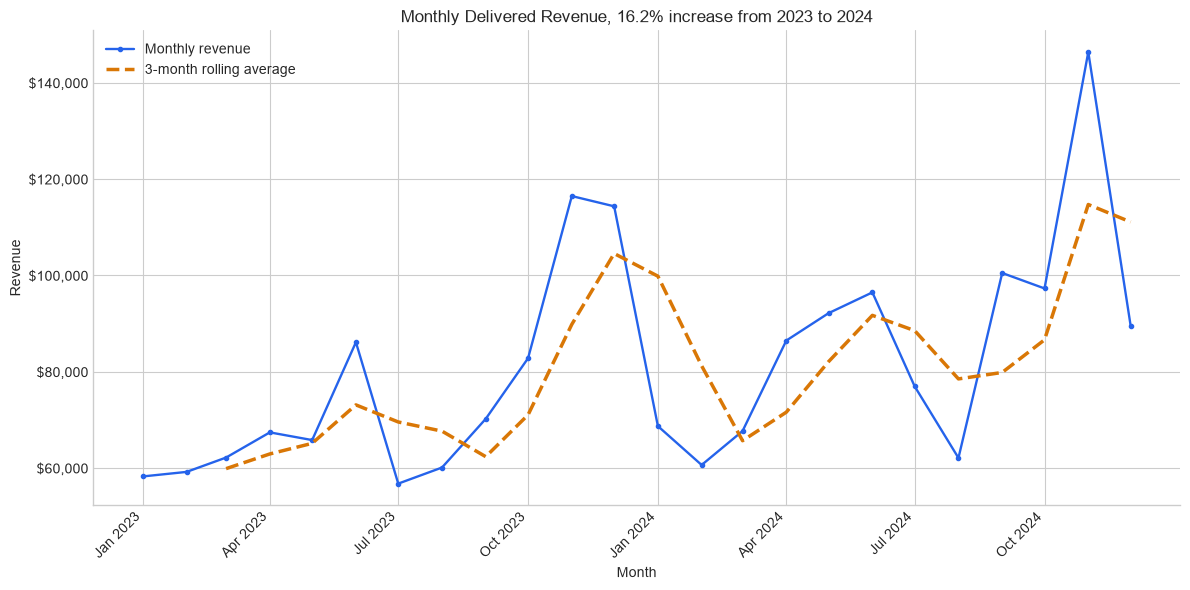

In [46]:
monthly_revenue_chart = monthly.copy()
monthly_revenue_chart["month_start"] = monthly_revenue_chart["month"].dt.to_timestamp()
monthly_revenue_chart["revenue_3_month_avg"] = (
    monthly_revenue_chart["monthly_revenue"].rolling(window=3, min_periods=3).mean()
)

fig, ax = setup_figure(figsize=(12, 6))
ax.plot(
    monthly_revenue_chart["month_start"],
    monthly_revenue_chart["monthly_revenue"],
    color=PRIMARY,
    linewidth=1.7,
    marker="o",
    markersize=3,
    label="Monthly revenue",
)
ax.plot(
    monthly_revenue_chart["month_start"],
    monthly_revenue_chart["revenue_3_month_avg"],
    color=HIGHLIGHT,
    linewidth=2.5,
    label="3-month rolling average",
    linestyle="--"
)
ax.set_title("Monthly Delivered Revenue, 16.2% increase from 2023 to 2024")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.set_xticks(
    monthly_revenue_chart["month_start"].iloc[::3],
    monthly_revenue_chart["month_start"].iloc[::3].dt.strftime("%b %Y"),
    rotation=45,
    ha="right",
)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

C2. Which categories bring the revenue?

Line revenue of delivered orders by product category.

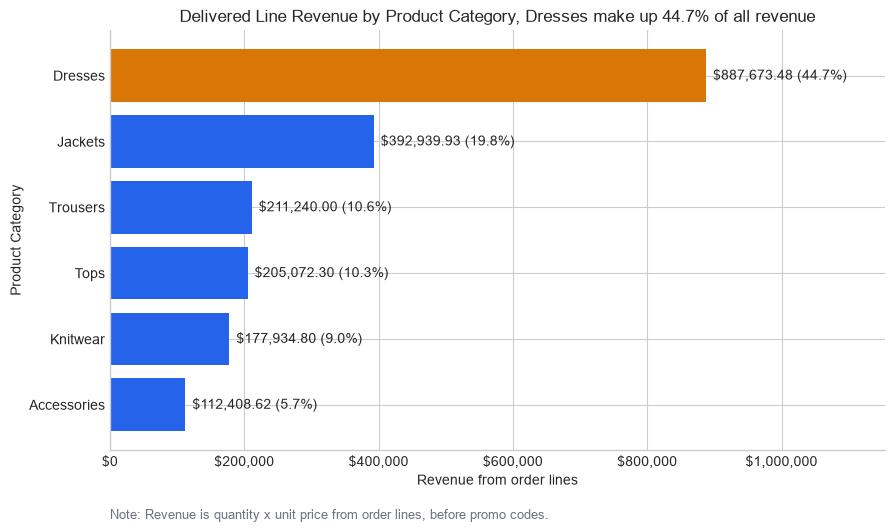

In [60]:
category_line_revenue = (
    order_lines
    .merge(
        products[["id", "category"]].rename(columns={"id": "product_id"}),
        on="product_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        delivered_orders[["id"]],
        left_on="order_id",
        right_on="id",
        how="inner",
        validate="many_to_one",
    )
    .assign(line_revenue=lambda df: df["quantity"] * df["unit_price"])
    .groupby("category", as_index=False)["line_revenue"]
    .sum()
)
category_line_revenue["revenue_share_pct"] = (
    category_line_revenue["line_revenue"]
    / category_line_revenue["line_revenue"].sum()
    * 100
)
category_line_revenue = category_line_revenue.sort_values(
    "line_revenue", ascending=True
)

bar_colors = [PRIMARY] * (len(category_line_revenue) - 1) + [HIGHLIGHT]

fig, ax = setup_figure(figsize=(10, 6))
bars = ax.barh(
    category_line_revenue["category"],
    category_line_revenue["line_revenue"],
    color=bar_colors,
)
for bar, share in zip(bars, category_line_revenue["revenue_share_pct"]):
    ax.annotate(
        f"${bar.get_width():,.2f} ({share:.1f}%)",
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
    )

ax.set_xlim(0, category_line_revenue["line_revenue"].max() * 1.3)
ax.set_title("Delivered Line Revenue by Product Category, Dresses make up 44.7% of all revenue")
ax.set_xlabel("Revenue from order lines")
ax.set_ylabel("Product Category")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.text(
    0,
    -0.14,
    "Note: Revenue is quantity x unit price from order lines, before promo codes.",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    color=NEUTRAL,
)
fig.subplots_adjust(bottom=0.18)
plt.show()

C3. Is an app order worth more than a web order?

Mean and median order value per channel, side by side.

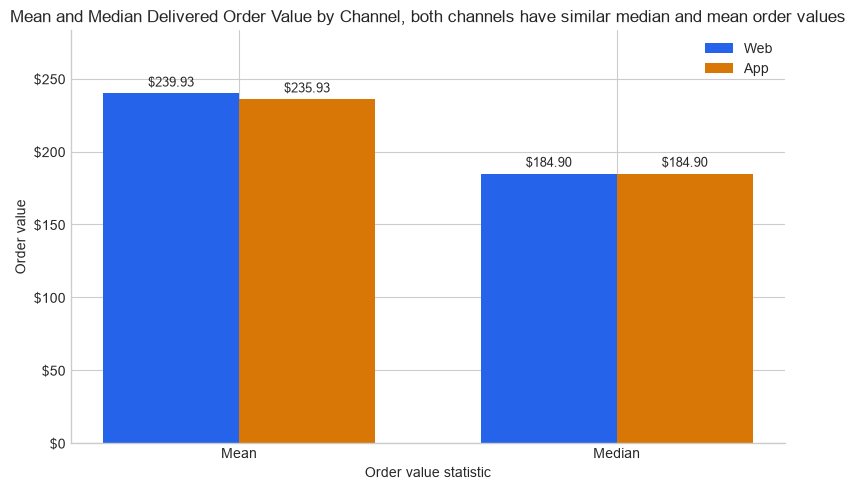

In [56]:
channel_order_amounts = orders_clean.loc[
    orders_clean["status"].eq("delivered"),
    ["channel", "order_total"],
].dropna(subset=["channel", "order_total"]).copy()
channel_order_amounts["channel"] = (
    channel_order_amounts["channel"].str.strip().str.lower()
)
channel_order_amounts = channel_order_amounts.loc[
    channel_order_amounts["channel"].isin(["web", "app"])
]

channel_order_summary = (
    channel_order_amounts.groupby("channel")["order_total"]
    .agg(mean_order_amount="mean", median_order_amount="median")
    .reindex(["web", "app"])
)

metric_positions = range(2)
bar_width = 0.36
web_values = [
    channel_order_summary.loc["web", "mean_order_amount"],
    channel_order_summary.loc["web", "median_order_amount"],
]
app_values = [
    channel_order_summary.loc["app", "mean_order_amount"],
    channel_order_summary.loc["app", "median_order_amount"],
]

fig, ax = setup_figure(figsize=(8, 5))
web_bars = ax.bar(
    [position - bar_width / 2 for position in metric_positions],
    web_values,
    width=bar_width,
    color=PRIMARY,
    label="Web",
)
app_bars = ax.bar(
    [position + bar_width / 2 for position in metric_positions],
    app_values,
    width=bar_width,
    color=HIGHLIGHT,
    label="App",
)

for bars in (web_bars, app_bars):
    ax.bar_label(
        bars,
        labels=[f"${bar.get_height():,.2f}" for bar in bars],
        padding=3,
        fontsize=9,
    )

ax.set_xticks(list(metric_positions), ["Mean", "Median"])
ax.set_ylim(0, max(web_values + app_values) * 1.18)
ax.set_title("Mean and Median Delivered Order Value by Channel, both channels have similar median and mean order values")
ax.set_xlabel("Order value statistic")
ax.set_ylabel("Order value")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

C4. Which styles carry the line revenue?

The top 10 styles by line revenue, with the first one in a different colour.

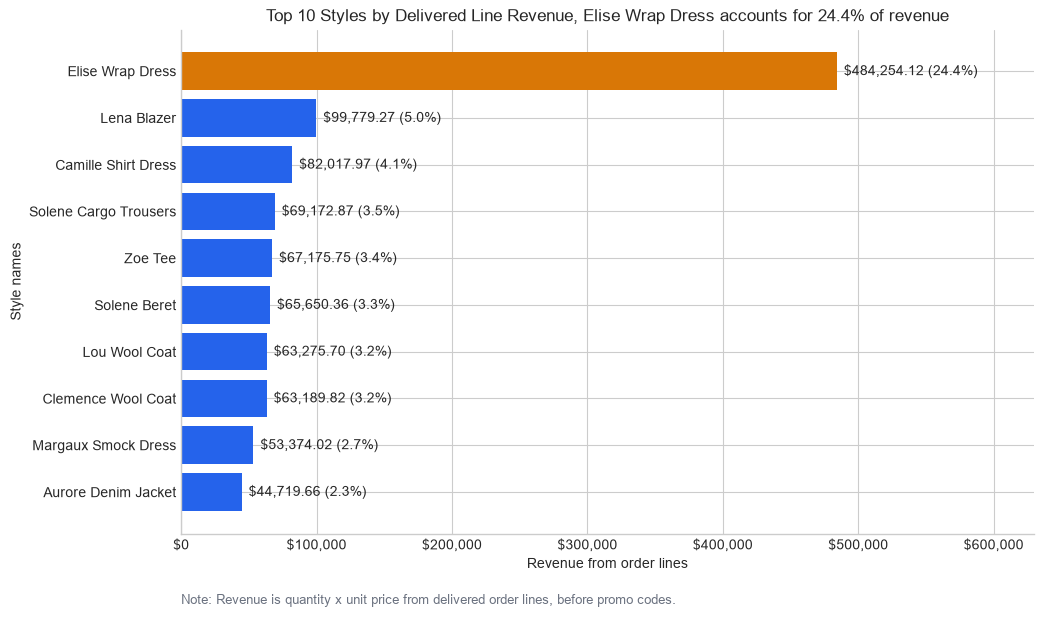

In [57]:
top_styles = style_revenue.head(10).copy()
top_styles["revenue_share_pct"] = (
    top_styles["revenue"] / style_revenue["revenue"].sum() * 100
)

bar_colors = [HIGHLIGHT] + [PRIMARY] * (len(top_styles) - 1)

fig, ax = setup_figure(figsize=(11, 7))
bars = ax.barh(
    top_styles["style"],
    top_styles["revenue"],
    color=bar_colors,
)
ax.invert_yaxis()

for bar, share in zip(bars, top_styles["revenue_share_pct"]):
    ax.annotate(
        f"${bar.get_width():,.2f} ({share:.1f}%)",
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
    )

ax.set_xlim(0, top_styles["revenue"].max() * 1.3)
ax.set_title("Top 10 Styles by Delivered Line Revenue, Elise Wrap Dress accounts for 24.4% of revenue")
ax.set_xlabel("Revenue from order lines")
ax.set_ylabel("Style names")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.text(
    0,
    -0.12,
    "Note: Revenue is quantity x unit price from delivered order lines, before promo codes.",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    color=NEUTRAL,
)
fig.subplots_adjust(bottom=0.16)
plt.show()

C5. When do orders come in?

Number of orders by day of the week and hour of the day, across both years.

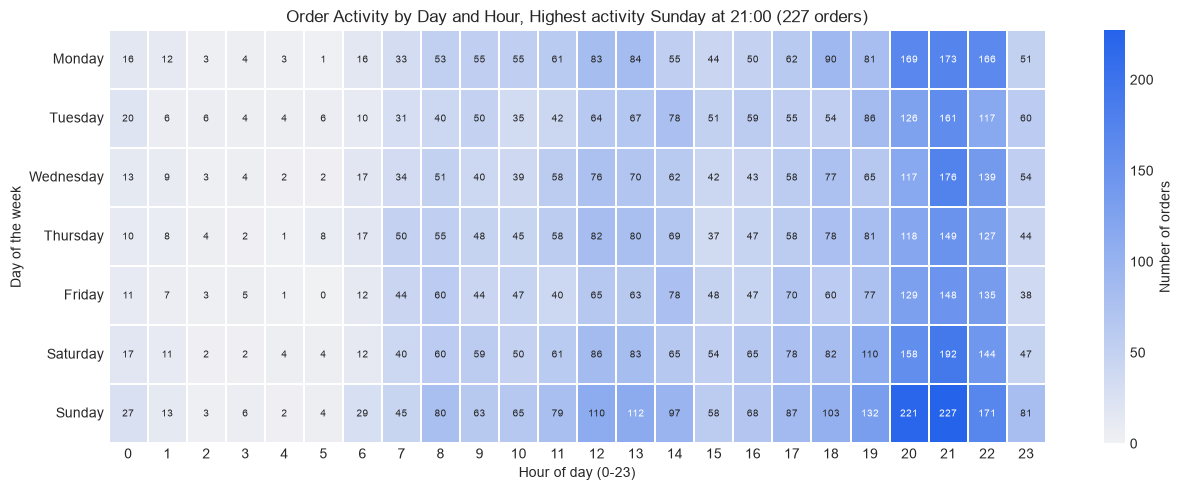

In [58]:
activity_by_day_hour = activity_orders.pivot_table(
    index="day_of_week",
    columns="hour",
    values="id",
    aggfunc="nunique",
    fill_value=0,
).reindex(index=weekday_order, columns=range(24), fill_value=0)

fig, ax = setup_figure(figsize=(13, 5))
sns.heatmap(
    activity_by_day_hour,
    cmap=sns.light_palette(PRIMARY, as_cmap=True),
    annot=True,
    fmt="d",
    annot_kws={"fontsize": 7},
    linewidths=0.25,
    linecolor="white",
    cbar_kws={"label": "Number of orders"},
    ax=ax,
)
ax.set_title("Order Activity by Day and Hour, Highest activity Sunday at 21:00 (227 orders)")
ax.set_xlabel("Hour of day (0-23)")
ax.set_ylabel("Day of the week")
ax.set_xticklabels([str(hour) for hour in range(24)], rotation=0)
ax.set_yticklabels(weekday_order, rotation=0)
fig.tight_layout()
plt.show()